# SpaceSoil — SoilGrids (خصائص التربة)

نوتبوك مستقلة لـ SoilGrids بنفس هيكل MODIS وNASA POWER، جاهزة للدمج بعدين.

**طريقة السحب:** WCS من ISRIC (بدون Earth Engine وبدون تسجيل دخول). الـ REST API متوقف مؤقتًا حسب توثيق ISRIC، فمش بنستخدمه. بنطلب مربع صغير حوالي كل نقطة (±10 كم) وبنقرا القيم منه.

**نقاط لازم تتعرف:**
- التربة **ثابتة مع الزمن**: هتطلع صف لكل (منطقة × عمق)، مش سلسلة زمنية. الدمج مع باقي الداتا بيكون على `region` بس.
- SoilGrids **تقديرات من موديل** (250 م)، مش قياسات عينات. التوثيق بيقول إن الموديل بيفسّر 30% لـ 70% من التباين، وإن الصحاري والمناطق الساحلية فيها بيانات عينات قليلة.
- الـ soil mask بتخفي المناطق **العمرانية والصحراء العارية والمياه**. ونقاطنا مراكز مدن، فممكن البكسل نفسه يكون بدون قيمة. النوتبوك بتوسّع دايرة البحث تدريجيًا (1.5 كم ثم 5 كم ثم 10 كم) وبتسجّل نصف القطر المستخدم في عمود `radius_m`.

شغّلي الخلايا بالترتيب.

In [1]:
!pip install -q rasterio pyproj requests pandas numpy matplotlib seaborn

In [3]:
import os, json, time
from datetime import datetime

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
from rasterio.transform import xy as raster_xy
from pyproj import Transformer

sns.set_theme(style="whitegrid")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/SpaceSoil/SoilGrids"
except ImportError:
    BASE_DIR = "SoilGrids_Data"

TILE_DIR = f"{BASE_DIR}/raw_tiles"
os.makedirs(TILE_DIR, exist_ok=True)
RAW_CSV = f"{BASE_DIR}/soilgrids_layers_long_raw.csv"
print("Saving to:", BASE_DIR)

Mounted at /content/drive
Saving to: /content/drive/MyDrive/SpaceSoil/SoilGrids


In [4]:
# Settings
WCS_URL = "https://maps.isric.org/mapserv"
CRS_URI = "http://www.opengis.net/def/crs/EPSG/0/152160"      # SoilGrids native (Homolosine)
IGH = "+proj=igh +datum=WGS84 +no_defs"

PROPERTIES = ["clay", "sand", "silt", "soc", "phh2o", "bdod", "nitrogen", "cec"]
OPTIONAL_PROPERTIES = ["wv0033", "wv1500"]     # water at field capacity / wilting point (skipped automatically if unavailable)
DEPTHS = ["0-5cm", "5-15cm", "15-30cm"]
THICKNESS_CM = {"0-5cm": 5, "5-15cm": 10, "15-30cm": 15}
MAIN_STAT = "Q0.5"                              # median
UNCERTAINTY_STATS = ["Q0.05", "Q0.95"]          # 90% prediction interval

# Mapped integer -> conventional unit (divide by this factor), from ISRIC documentation
CONV = {"bdod": 100, "cec": 10, "clay": 10, "nitrogen": 100, "soc": 10, "phh2o": 10,
        "sand": 10, "silt": 10, "wv0033": 10, "wv1500": 10}
UNITS = {"bdod": "kg/dm3", "cec": "cmol(c)/kg", "clay": "%", "nitrogen": "g/kg", "soc": "g/kg",
         "phh2o": "pH", "sand": "%", "silt": "%", "wv0033": "%", "wv1500": "%"}

HALF_WIDTH_M = 10000          # size of the tile requested around each point
RADII_M = [0, 1500, 5000, 10000]   # 0 = center pixel only; widen until a valid pixel is found

# Same coordinates as the MODIS / NASA POWER notebooks: (latitude, longitude)
regions = {
    "Mansoura":      (31.04, 31.38),
    "Fayoum":        (29.31, 30.84),
    "Ismailia":      (30.60, 32.27),
    "Luxor":         (25.69, 32.64),
    "Marsa Matrouh": (31.35, 27.24),
}

to_igh = Transformer.from_crs("EPSG:4326", IGH, always_xy=True)
points = {}
for name, (lat, lon) in regions.items():
    x, y = to_igh.transform(lon, lat)
    points[name] = (x, y)
    print(f"{name:14s} lat={lat:6.2f} lon={lon:6.2f} -> igh x={x:12.0f} y={y:12.0f}")

Mansoura       lat= 31.04 lon= 31.38 -> igh x=     3471208 y=     3455357
Fayoum         lat= 29.31 lon= 30.84 -> igh x=     3421123 y=     3262774
Ismailia       lat= 30.60 lon= 32.27 -> igh x=     3557090 y=     3406376
Luxor          lat= 25.69 lon= 32.64 -> igh x=     3604419 y=     2859798
Marsa Matrouh  lat= 31.35 lon= 27.24 -> igh x=     3077199 y=     3489866


## 1. Data Collection helpers (WCS)

In [5]:
def fetch_tile(prop, depth, stat, region):
    """Download a small GeoTIFF around the region point. Cached on disk."""
    cid = f"{prop}_{depth}_{stat}"
    path = f"{TILE_DIR}/{cid}__{region.replace(' ', '_')}.tif"
    if os.path.exists(path):
        return path, False

    x, y = points[region]
    params = [
        ("map", f"/map/{prop}.map"),
        ("SERVICE", "WCS"),
        ("VERSION", "2.0.1"),
        ("REQUEST", "GetCoverage"),
        ("COVERAGEID", cid),
        ("FORMAT", "GEOTIFF_INT16"),
        ("SUBSET", f"X({x - HALF_WIDTH_M:.0f},{x + HALF_WIDTH_M:.0f})"),
        ("SUBSET", f"Y({y - HALF_WIDTH_M:.0f},{y + HALF_WIDTH_M:.0f})"),
        ("SUBSETTINGCRS", CRS_URI),
        ("OUTPUTCRS", CRS_URI),
    ]

    last = ""
    for attempt in range(3):
        try:
            r = requests.get(WCS_URL, params=params, timeout=120)
            if r.status_code == 200 and r.content[:4] in (b"II*\x00", b"MM\x00*", b"II+\x00"):
                with open(path, "wb") as fh:
                    fh.write(r.content)
                return path, True
            snippet = r.text[:200].replace("\n", " ") if "xml" in r.headers.get("content-type", "") or "text" in r.headers.get("content-type", "") else ""
            last = f"HTTP {r.status_code} {snippet}"
        except requests.RequestException as e:
            last = f"{type(e).__name__}: {str(e)[:120]}"
        time.sleep(3 * (attempt + 1))
    raise RuntimeError(last)


def window_stats(arr, valid, xs, ys, x, y, radii):
    """Pure numpy: value from center pixel, widening the search radius until a valid pixel exists."""
    dist = np.hypot(xs - x, ys - y)
    center_idx = np.argmin(dist)
    center_valid = bool(valid.flat[center_idx])
    for r in radii:
        if r == 0:
            mask = np.zeros(arr.shape, bool)
            mask.flat[center_idx] = True
            mask &= valid
        else:
            mask = valid & (dist <= r)
        if mask.any():
            return {"value_raw": float(np.median(arr[mask])), "radius_m": r,
                    "n_valid_px": int(mask.sum()), "center_valid": center_valid}
    return {"value_raw": np.nan, "radius_m": np.nan, "n_valid_px": 0, "center_valid": center_valid}


def read_tile(path, region):
    x, y = points[region]
    with rasterio.open(path) as ds:
        arr = ds.read(1).astype("float64")
        nodata = ds.nodata
        rows, cols = np.indices(arr.shape)
        xs, ys = raster_xy(ds.transform, rows.ravel(), cols.ravel(), offset="center")
        xs = np.array(xs).reshape(arr.shape)
        ys = np.array(ys).reshape(arr.shape)
    valid = arr != -32768
    if nodata is not None:
        valid &= arr != nodata
    return window_stats(arr, valid, xs, ys, x, y, RADII_M)

In [6]:
# Smoke test: one tile, so any connection problem shows up immediately
p, downloaded = fetch_tile("clay", "0-5cm", MAIN_STAT, "Mansoura")
print("Tile:", p, "| downloaded now:", downloaded)
print(read_tile(p, "Mansoura"))

Tile: /content/drive/MyDrive/SpaceSoil/SoilGrids/raw_tiles/clay_0-5cm_Q0.5__Mansoura.tif | downloaded now: True
{'value_raw': 0.0, 'radius_m': 0, 'n_valid_px': 1, 'center_valid': True}


## 2. Extraction for the five regions

In [7]:
# Load what is already saved (so a restart does not repeat work)
if os.path.exists(RAW_CSV):
    soil_raw = pd.read_csv(RAW_CSV)
    records = soil_raw.to_dict("records")
    done = set(zip(soil_raw["region"], soil_raw["property"], soil_raw["depth"], soil_raw["stat"]))
else:
    records, done = [], set()
print("Already done:", len(done))

failed = []
all_props = PROPERTIES + OPTIONAL_PROPERTIES
stat_order = [MAIN_STAT] + UNCERTAINTY_STATS          # main stat first, uncertainty after
t_start = time.time()

for stat in stat_order:
    for prop in all_props:
        for depth in DEPTHS:
            new_rows = 0
            for region, (lat, lon) in regions.items():
                key = (region, prop, depth, stat)
                if key in done:
                    continue
                try:
                    path, downloaded = fetch_tile(prop, depth, stat, region)
                    res = read_tile(path, region)
                except Exception as e:
                    failed.append((prop, depth, stat, region, str(e)[:150]))
                    continue
                records.append({"region": region, "latitude": lat, "longitude": lon,
                                "property": prop, "depth": depth, "stat": stat,
                                "coverage_id": f"{prop}_{depth}_{stat}", **res})
                done.add(key)
                new_rows += 1
                if downloaded:
                    time.sleep(0.5)
            if new_rows:
                pd.DataFrame(records).to_csv(RAW_CSV, index=False)
        print(f"{stat} | {prop:9s} done | {(time.time() - t_start) / 60:5.1f} min | rows: {len(records)} | failed: {len(failed)}")

soil_raw = pd.DataFrame(records)
print("\nFailed requests:", len(failed))
bad_props = sorted({f[0] for f in failed})
print("Properties with at least one failure:", bad_props)
for f in failed[:5]:
    print("  e.g.", f)

Already done: 0
Q0.5 | clay      done |   0.2 min | rows: 15 | failed: 0
Q0.5 | sand      done |   0.5 min | rows: 30 | failed: 0
Q0.5 | silt      done |   0.7 min | rows: 45 | failed: 0
Q0.5 | soc       done |   1.0 min | rows: 60 | failed: 0
Q0.5 | phh2o     done |   1.3 min | rows: 75 | failed: 0
Q0.5 | bdod      done |   1.5 min | rows: 90 | failed: 0
Q0.5 | nitrogen  done |   1.8 min | rows: 105 | failed: 0
Q0.5 | cec       done |   2.0 min | rows: 120 | failed: 0
Q0.5 | wv0033    done |   2.3 min | rows: 135 | failed: 0
Q0.5 | wv1500    done |   2.7 min | rows: 150 | failed: 0
Q0.05 | clay      done |   3.0 min | rows: 165 | failed: 0
Q0.05 | sand      done |   3.2 min | rows: 180 | failed: 0
Q0.05 | silt      done |   3.5 min | rows: 195 | failed: 0
Q0.05 | soc       done |   3.8 min | rows: 210 | failed: 0
Q0.05 | phh2o     done |   4.0 min | rows: 225 | failed: 0
Q0.05 | bdod      done |   4.3 min | rows: 240 | failed: 0
Q0.05 | nitrogen  done |   4.5 min | rows: 255 | failed:

## 3. Raw dataset + Data Quality Analysis

In [8]:
# Convert mapped integers to conventional units
soil_raw["value"] = soil_raw["value_raw"] / soil_raw["property"].map(CONV)
soil_raw["unit"] = soil_raw["property"].map(UNITS)

print("Shape:", soil_raw.shape)
display(soil_raw.dtypes.to_frame("dtype").T)

print("Duplicates (region, property, depth, stat):",
      int(soil_raw.duplicated(["region", "property", "depth", "stat"]).sum()))

print("\nMissing values (main stat) by property:")
main_raw = soil_raw[soil_raw["stat"] == MAIN_STAT]
display(main_raw.groupby("property")["value"].apply(lambda s: int(s.isna().sum())).to_frame("missing"))

print("Search radius used (main stat) - how many values needed a wider search:")
display(pd.crosstab(main_raw["region"], main_raw["radius_m"].fillna(-1).astype(int).rename("radius_m")))

Shape: (450, 13)


,region,latitude,longitude,property,depth,stat,coverage_id,value_raw,radius_m,n_valid_px,center_valid,value,unit
dtype,object,float64,float64,object,object,object,object,float64,int64,int64,bool,float64,object


Duplicates (region, property, depth, stat): 0

Missing values (main stat) by property:


,missing
property,
bdod,0
cec,0
clay,0
nitrogen,0
phh2o,0
sand,0
silt,0
soc,0
wv0033,0


Search radius used (main stat) - how many values needed a wider search:


radius_m,0
region,
Fayoum,30
Ismailia,30
Luxor,30
Mansoura,30
Marsa Matrouh,30


## 4. Cleaning

- القيم اتحولت لوحدات مألوفة (clay % ، soc g/kg ، pH ، bdod kg/dm3 ...).
- أي قيمة خارج المدى المعقول علميًا بتتحول NaN وبتتسجل.
- الرمل + السلت + الطين اتنين موديلات منفصلة فمجموعهم ممكن ميبقاش 100 بالظبط، فبنعمل نسخة معادلة (normalized) لتصنيف القوام بس.

In [9]:
# Wide table (one row per region x depth), main statistic only
wide = (main_raw.pivot_table(index=["region", "depth"], columns="property", values="value")
                .reset_index())
radius = (main_raw.pivot_table(index=["region", "depth"], columns="property", values="radius_m")
                  .add_suffix("_radius_m").reset_index())
wide = wide.merge(radius, on=["region", "depth"], how="left")
wide["radius_m_max"] = wide[[c for c in wide.columns if c.endswith("_radius_m")]].max(axis=1)

# Plausibility ranges (conventional units)
RANGES = {"clay": (0, 100), "sand": (0, 100), "silt": (0, 100), "soc": (0, 600),
          "phh2o": (3, 10.5), "bdod": (0.5, 2.2), "nitrogen": (0, 50), "cec": (0, 150),
          "wv0033": (0, 70), "wv1500": (0, 60)}

clean = wide.copy()
flagged = []
for prop, (lo, hi) in RANGES.items():
    if prop in clean.columns:
        bad = ~clean[prop].between(lo, hi) & clean[prop].notna()
        for _, row in clean[bad].iterrows():
            flagged.append((row["region"], row["depth"], prop, row[prop]))
        clean.loc[bad, prop] = np.nan

print("Values set to NaN (outside plausible range):", len(flagged))
for f in flagged:
    print("  ", f)

# Texture sum check
clean["texture_sum"] = clean[["sand", "silt", "clay"]].sum(axis=1, min_count=3)
display(clean[["region", "depth", "sand", "silt", "clay", "texture_sum"]].round(1))

Values set to NaN (outside plausible range): 30
   ('Fayoum', '0-5cm', 'phh2o', 0.0)
   ('Fayoum', '15-30cm', 'phh2o', 0.0)
   ('Fayoum', '5-15cm', 'phh2o', 0.0)
   ('Ismailia', '0-5cm', 'phh2o', 0.0)
   ('Ismailia', '15-30cm', 'phh2o', 0.0)
   ('Ismailia', '5-15cm', 'phh2o', 0.0)
   ('Luxor', '0-5cm', 'phh2o', 0.0)
   ('Luxor', '15-30cm', 'phh2o', 0.0)
   ('Luxor', '5-15cm', 'phh2o', 0.0)
   ('Mansoura', '0-5cm', 'phh2o', 0.0)
   ('Mansoura', '15-30cm', 'phh2o', 0.0)
   ('Mansoura', '5-15cm', 'phh2o', 0.0)
   ('Marsa Matrouh', '0-5cm', 'phh2o', 0.0)
   ('Marsa Matrouh', '15-30cm', 'phh2o', 0.0)
   ('Marsa Matrouh', '5-15cm', 'phh2o', 0.0)
   ('Fayoum', '0-5cm', 'bdod', 0.0)
   ('Fayoum', '15-30cm', 'bdod', 0.0)
   ('Fayoum', '5-15cm', 'bdod', 0.0)
   ('Ismailia', '0-5cm', 'bdod', 0.0)
   ('Ismailia', '15-30cm', 'bdod', 0.0)
   ('Ismailia', '5-15cm', 'bdod', 0.0)
   ('Luxor', '0-5cm', 'bdod', 0.0)
   ('Luxor', '15-30cm', 'bdod', 0.0)
   ('Luxor', '5-15cm', 'bdod', 0.0)
   ('Mansoura', 

property,region,depth,sand,silt,clay,texture_sum
0,Fayoum,0-5cm,0.0,0.0,0.0,0.0
1,Fayoum,15-30cm,0.0,0.0,0.0,0.0
2,Fayoum,5-15cm,0.0,0.0,0.0,0.0
3,Ismailia,0-5cm,0.0,0.0,0.0,0.0
4,Ismailia,15-30cm,0.0,0.0,0.0,0.0
5,Ismailia,5-15cm,0.0,0.0,0.0,0.0
6,Luxor,0-5cm,0.0,0.0,0.0,0.0
7,Luxor,15-30cm,0.0,0.0,0.0,0.0
8,Luxor,5-15cm,0.0,0.0,0.0,0.0
9,Mansoura,0-5cm,0.0,0.0,0.0,0.0


## 5. Outlier Detection

In [10]:
# With only 5 regions a statistical outlier test has little power, so we combine
# (a) robust z-score across regions (median / MAD) and (b) depth-consistency checks.
core = [p for p in PROPERTIES + OPTIONAL_PROPERTIES if p in clean.columns]
surface = clean[clean["depth"] == "0-5cm"].set_index("region")[core]

med = surface.median()
mad = (surface - med).abs().median().replace(0, np.nan)
robust_z = 0.6745 * (surface - med) / mad
print("Modified z-score (0-5 cm, |z| > 3.5 = flag):")
display(robust_z.round(2))

flags = [(r, p, round(robust_z.loc[r, p], 2)) for r in robust_z.index for p in robust_z.columns
         if pd.notna(robust_z.loc[r, p]) and abs(robust_z.loc[r, p]) > 3.5]
print("Flagged values:", flags if flags else "none")

# SOC normally does not increase with depth in mineral soils: list exceptions for manual review
soc_piv = clean.pivot(index="region", columns="depth", values="soc")[DEPTHS] if "soc" in clean.columns else None
if soc_piv is not None:
    exceptions = soc_piv[(soc_piv["0-5cm"] < soc_piv["5-15cm"]) | (soc_piv["5-15cm"] < soc_piv["15-30cm"])]
    print("\nRegions where SOC increases with depth (review):", list(exceptions.index) if len(exceptions) else "none")

Modified z-score (0-5 cm, |z| > 3.5 = flag):


property,clay,sand,silt,soc,phh2o,bdod,nitrogen,cec,wv0033,wv1500
region,,,,,,,,,,
Fayoum,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ismailia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Luxor,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mansoura,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marsa Matrouh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Flagged values: none

Regions where SOC increases with depth (review): none


## 6. Feature Engineering

- `texture_class`: قوام التربة حسب تصنيف USDA من الرمل/السلت/الطين (معادلة لمجموع 100).
- `*_0_30`: متوسط 0-30 سم موزون بسمك الطبقة (5/10/15 سم). تبسيط، مش موزون بالكثافة.
- `om_pct_approx`: المادة العضوية التقريبية = الكربون العضوي × 1.724 (معامل Van Bemmelen الشائع)، قيمة تقريبية.
- `uncertainty_ratio`: عرض فترة التنبؤ 90% ÷ الوسيط، من (Q0.95 - Q0.05) / Q0.50. كل ما زادت، التقدير أقل ثقة.

مفيش "Soil Quality Score" مركّب، لأن مفيش وزن علمي متفق عليه يربط الخصائص دي بدرجة واحدة؛ فضلت المؤشرات المعروفة بس.

In [11]:
def usda_texture(sand, silt, clay):
    """USDA texture class from percentages (sand + silt + clay ~ 100)."""
    if any(pd.isna(v) for v in (sand, silt, clay)):
        return None
    if silt + 1.5 * clay < 15:
        return "Sand"
    if silt + 1.5 * clay >= 15 and silt + 2 * clay < 30:
        return "Loamy sand"
    if (7 <= clay < 20 and sand > 52 and silt + 2 * clay >= 30) or (clay < 7 and silt < 50 and silt + 2 * clay >= 30):
        return "Sandy loam"
    if 7 <= clay < 27 and 28 <= silt < 50 and sand <= 52:
        return "Loam"
    if (silt >= 50 and 12 <= clay < 27) or (50 <= silt < 80 and clay < 12):
        return "Silt loam"
    if silt >= 80 and clay < 12:
        return "Silt"
    if 20 <= clay < 35 and silt < 28 and sand > 45:
        return "Sandy clay loam"
    if 27 <= clay < 40 and 20 < sand <= 45:
        return "Clay loam"
    if 27 <= clay < 40 and sand <= 20:
        return "Silty clay loam"
    if clay >= 35 and sand > 45:
        return "Sandy clay"
    if clay >= 40 and silt >= 40:
        return "Silty clay"
    if clay >= 40 and sand <= 45 and silt < 40:
        return "Clay"
    return None


def classify_rows(df):
    s = df[["sand", "silt", "clay"]].sum(axis=1, min_count=3)
    norm = df[["sand", "silt", "clay"]].div(s, axis=0) * 100
    return [usda_texture(a, b, c) for a, b, c in zip(norm["sand"], norm["silt"], norm["clay"])]


feat = clean.copy()
feat["texture_class"] = classify_rows(feat)
if "soc" in feat.columns:
    feat["om_pct_approx"] = feat["soc"] / 10 * 1.724

# Uncertainty ratio from the quantile layers
q = soil_raw[soil_raw["stat"].isin(UNCERTAINTY_STATS + [MAIN_STAT])].pivot_table(
        index=["region", "depth", "property"], columns="stat", values="value").reset_index()
if all(c in q.columns for c in UNCERTAINTY_STATS + [MAIN_STAT]):
    q["uncertainty_ratio"] = np.where(q[MAIN_STAT] > 0, (q["Q0.95"] - q["Q0.05"]) / q[MAIN_STAT], np.nan)
    unc = q.pivot_table(index=["region", "depth"], columns="property", values="uncertainty_ratio").add_suffix("_unc").reset_index()
    feat = feat.merge(unc, on=["region", "depth"], how="left")
else:
    print("Uncertainty layers not available - uncertainty columns skipped")

soil_by_depth = feat.sort_values(["region", "depth"]).reset_index(drop=True)
display(soil_by_depth[["region", "depth", "sand", "silt", "clay", "texture_class", "soc", "phh2o", "bdod", "radius_m_max"]].round(2))

property,region,depth,sand,silt,clay,texture_class,soc,phh2o,bdod,radius_m_max
0,Fayoum,0-5cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
1,Fayoum,15-30cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
2,Fayoum,5-15cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
3,Ismailia,0-5cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
4,Ismailia,15-30cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
5,Ismailia,5-15cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
6,Luxor,0-5cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
7,Luxor,15-30cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
8,Luxor,5-15cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0
9,Mansoura,0-5cm,0.0,0.0,0.0,None,0.0,NaN,NaN,0.0


In [12]:
# 0-30 cm thickness-weighted summary: ONE ROW PER REGION (ready to merge on 'region')
num_cols = [c for c in core if c in soil_by_depth.columns] + (["om_pct_approx"] if "om_pct_approx" in soil_by_depth.columns else [])
w = soil_by_depth["depth"].map(THICKNESS_CM)

def weighted(g):
    ww = w.loc[g.index]
    out = {}
    for c in num_cols:
        ok = g[c].notna()
        out[f"{c}_0_30"] = np.average(g.loc[ok, c], weights=ww[ok]) if ok.any() else np.nan
    out["radius_m_max"] = g["radius_m_max"].max()
    return pd.Series(out)

soil_0_30 = soil_by_depth.groupby("region").apply(weighted).reset_index()
soil_0_30["texture_class_0_30"] = classify_rows(
    soil_0_30.rename(columns={"sand_0_30": "sand", "silt_0_30": "silt", "clay_0_30": "clay"}))
display(soil_0_30.round(2))

/tmp/ipykernel_9655/3673791439.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  soil_0_30 = soil_by_depth.groupby("region").apply(weighted).reset_index()


,region,clay_0_30,sand_0_30,silt_0_30,soc_0_30,phh2o_0_30,bdod_0_30,nitrogen_0_30,cec_0_30,wv0033_0_30,wv1500_0_30,om_pct_approx_0_30,radius_m_max,texture_class_0_30
0,Fayoum,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,None
1,Ismailia,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,None
2,Luxor,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,None
3,Mansoura,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,None
4,Marsa Matrouh,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,None


## 7. EDA

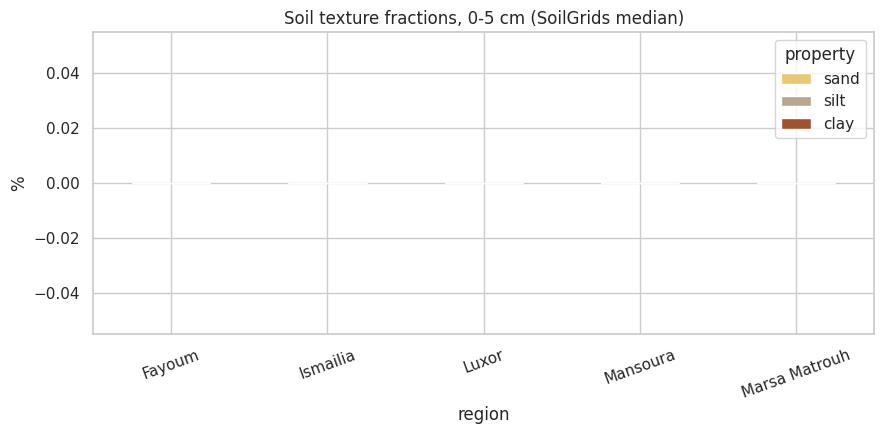

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
top = soil_by_depth[soil_by_depth["depth"] == "0-5cm"].set_index("region")[["sand", "silt", "clay"]]
top.plot(kind="bar", stacked=True, ax=ax, color=["#e8c872", "#b8a78c", "#a0522d"])
ax.set_ylabel("%")
ax.set_title("Soil texture fractions, 0-5 cm (SoilGrids median)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

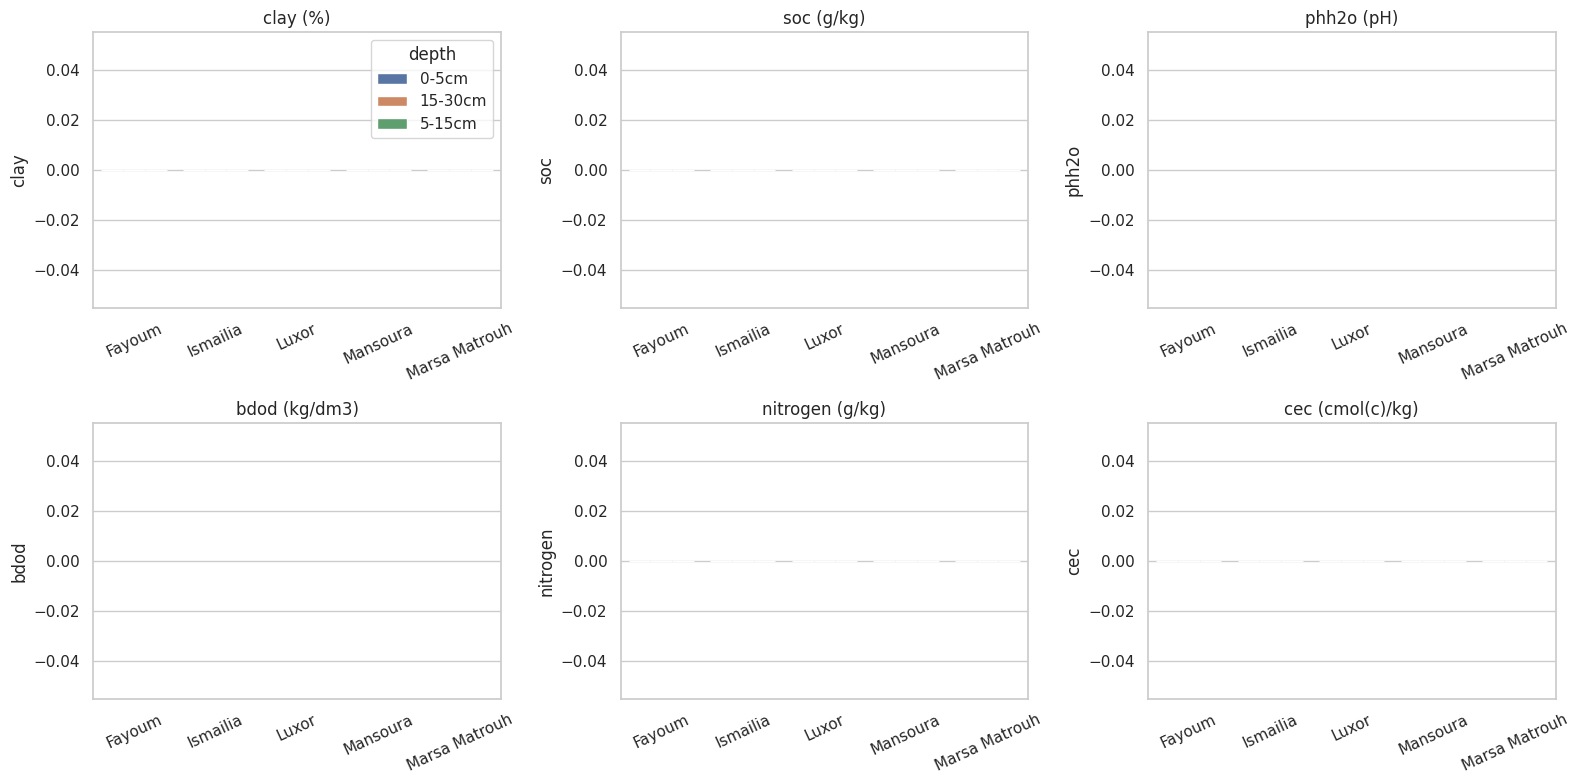

In [14]:
show = [p for p in ["clay", "soc", "phh2o", "bdod", "nitrogen", "cec"] if p in soil_by_depth.columns]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, p in zip(axes.ravel(), show):
    sns.barplot(data=soil_by_depth, x="region", y=p, hue="depth", ax=ax)
    ax.set_title(f"{p} ({UNITS[p]})")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    if ax is not axes.ravel()[0]:
        ax.get_legend().remove()
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


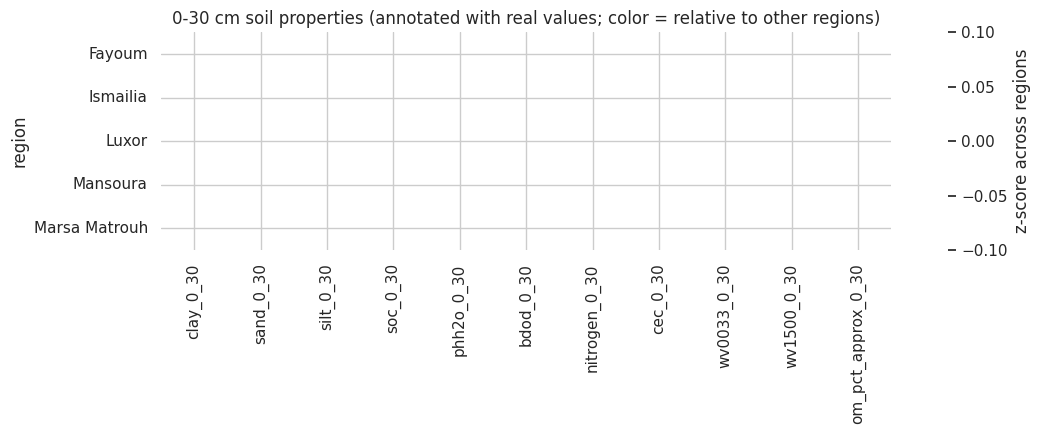

In [15]:
cols = [c for c in soil_0_30.columns if c.endswith("_0_30") and c != "texture_class_0_30"]
vals = soil_0_30.set_index("region")[cols]
z = (vals - vals.mean()) / vals.std(ddof=0).replace(0, np.nan)

plt.figure(figsize=(11, 4.5))
sns.heatmap(z, annot=vals.round(1), fmt="", cmap="coolwarm", center=0, cbar_kws={"label": "z-score across regions"})
plt.title("0-30 cm soil properties (annotated with real values; color = relative to other regions)")
plt.tight_layout()
plt.show()

## 8. Validation

In [16]:
checks = []
expected_rows = len(regions) * len(DEPTHS)
checks.append(("5 regions present", soil_by_depth["region"].nunique() == len(regions), soil_by_depth["region"].nunique()))
checks.append(("rows = regions x depths", len(soil_by_depth) == expected_rows, f"{len(soil_by_depth)} / {expected_rows}"))
checks.append(("no duplicate region/depth", not soil_by_depth.duplicated(["region", "depth"]).any(), ""))

core_main = [p for p in PROPERTIES if p in soil_by_depth.columns]
n_missing = int(soil_by_depth[core_main].isna().sum().sum())
checks.append(("no missing in core properties", n_missing == 0, f"{n_missing} missing"))

ts = soil_by_depth["texture_sum"].dropna()
checks.append(("sand+silt+clay within 90-110", bool(ts.between(90, 110).all()) if len(ts) else False,
               f"min {ts.min():.0f}, max {ts.max():.0f}" if len(ts) else "no data"))
checks.append(("texture class assigned", bool(soil_by_depth["texture_class"].notna().all()), ""))

within_pixel = (soil_by_depth["radius_m_max"] == 0).mean() * 100
checks.append(("values taken from the exact pixel (info)", True, f"{within_pixel:.0f}% of rows; others used a wider search radius"))

for name, ok, detail in checks:
    print(("PASS" if ok else "FAIL"), "-", name, "|", detail)

print("\nRows that relied on a wider radius than the center pixel:")
display(soil_by_depth.loc[soil_by_depth["radius_m_max"] > 0, ["region", "depth", "radius_m_max"]]
        .drop_duplicates("region"))

PASS - 5 regions present | 5
PASS - rows = regions x depths | 15 / 15
PASS - no duplicate region/depth | 
FAIL - no missing in core properties | 30 missing
FAIL - sand+silt+clay within 90-110 | min 0, max 0
FAIL - texture class assigned | 
PASS - values taken from the exact pixel (info) | 100% of rows; others used a wider search radius

Rows that relied on a wider radius than the center pixel:


property,region,depth,radius_m_max


## 9. Metadata + Export

In [17]:
by_depth_path = f"{BASE_DIR}/soilgrids_by_depth.csv"
summary_path = f"{BASE_DIR}/soilgrids_0_30cm_summary.csv"
meta_path = f"{BASE_DIR}/soilgrids_metadata.json"
readme_path = f"{BASE_DIR}/soilgrids_README.md"

soil_by_depth.to_csv(by_depth_path, index=False)
soil_0_30.to_csv(summary_path, index=False)
# raw long table already saved at RAW_CSV

meta = {
    "source": "ISRIC SoilGrids 2.0 via WCS (maps.isric.org)",
    "license": "CC BY 4.0 (ISRIC)",
    "properties": PROPERTIES + OPTIONAL_PROPERTIES,
    "units_after_conversion": UNITS,
    "conversion_factors": CONV,
    "depths": DEPTHS,
    "main_statistic": MAIN_STAT,
    "uncertainty_statistics": UNCERTAINTY_STATS,
    "resolution_m": 250,
    "regions": {k: {"latitude": v[0], "longitude": v[1]} for k, v in regions.items()},
    "extraction": f"median of valid pixels; search radius widened through {RADII_M} m until a valid pixel was found (radius_m columns)",
    "rows": {"by_depth": int(len(soil_by_depth)), "summary_0_30": int(len(soil_0_30)), "raw_long": int(len(soil_raw))},
    "failed_requests": len(failed),
    "merge_key": "region (static data, no date)",
    "created": datetime.now().isoformat(timespec="seconds"),
}
json.dump(meta, open(meta_path, "w"), indent=2)

readme = f'''# SoilGrids dataset (SpaceSoil)

**Source:** ISRIC SoilGrids 2.0, WCS service. License CC BY 4.0, cite ISRIC.
**Properties:** {", ".join(PROPERTIES)} (+ optional: {", ".join(OPTIONAL_PROPERTIES)}) at depths {", ".join(DEPTHS)}.
**Statistic:** median (Q0.5). Q0.05 and Q0.95 used only for the uncertainty ratio.

## Files
- soilgrids_by_depth.csv: one row per region and depth, with texture class and uncertainty.
- soilgrids_0_30cm_summary.csv: one row per region (thickness-weighted 0-30 cm). Use this for merging on `region`.
- soilgrids_layers_long_raw.csv: raw long table (mapped integers + converted values).
- raw_tiles/: the downloaded GeoTIFF tiles.

## Cleaning
Mapped integers divided by the ISRIC conversion factors; values outside plausible ranges set to NaN; texture fractions normalized to 100 only for the texture class.

## Limitations
- Values are model predictions, not direct soil sample measurements; ISRIC reports 30-70% of variation explained and sparse sample data in deserts and coastal areas.
- The soil mask excludes urban, bare surface and water; points are city centers, so values may come from a wider search radius (see radius_m columns).
- Static data: no time dimension.
'''
open(readme_path, "w").write(readme)

print("Saved:")
for p in [by_depth_path, summary_path, RAW_CSV, meta_path, readme_path]:
    print(" -", p)

Saved:
 - /content/drive/MyDrive/SpaceSoil/SoilGrids/soilgrids_by_depth.csv
 - /content/drive/MyDrive/SpaceSoil/SoilGrids/soilgrids_0_30cm_summary.csv
 - /content/drive/MyDrive/SpaceSoil/SoilGrids/soilgrids_layers_long_raw.csv
 - /content/drive/MyDrive/SpaceSoil/SoilGrids/soilgrids_metadata.json
 - /content/drive/MyDrive/SpaceSoil/SoilGrids/soilgrids_README.md
